<a href="https://colab.research.google.com/github/dmitrijg08/Lab1_GroupProject/blob/main/%D0%9B%D0%A07_%D0%93%D1%83%D1%81%D0%B0%D0%BA_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

=== Logistic Regression ===
Accuracy: 0.8932
F1 Score: 0.8941

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



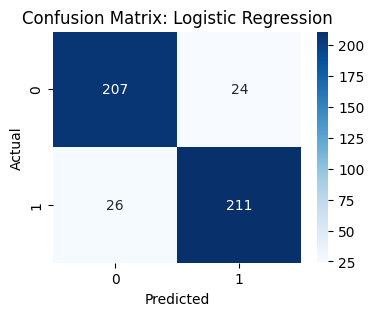

--------------------------------------------------
=== Decision Tree ===
Accuracy: 0.8632
F1 Score: 0.8632

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86       231
           1       0.87      0.85      0.86       237

    accuracy                           0.86       468
   macro avg       0.86      0.86      0.86       468
weighted avg       0.86      0.86      0.86       468



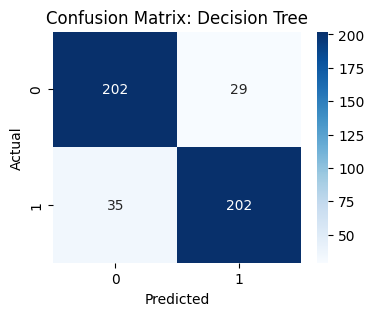

--------------------------------------------------
=== Support Vector Machine (SVC) ===
Accuracy: 0.9594
F1 Score: 0.9600

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       231
           1       0.96      0.96      0.96       237

    accuracy                           0.96       468
   macro avg       0.96      0.96      0.96       468
weighted avg       0.96      0.96      0.96       468



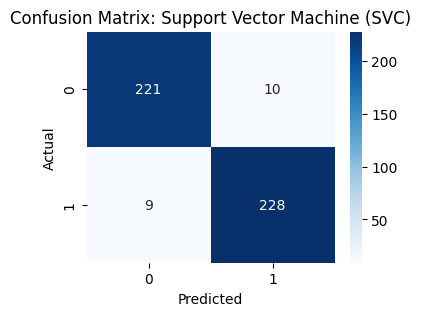

--------------------------------------------------


In [3]:
df = pd.read_csv('data.csv')

X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Support Vector Machine (SVC)": SVC(random_state=42)
}

for name, model in models.items():
    if name == "Decision Tree":
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    print(f"=== {name} ===")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    print("-" * 50)

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Пропуски в даних відсутні, дублікатів також не виявлено. Усі ознаки мають числовий формат (int або float). Це свідчить про високу якість зібраного датасету — дані повністю готові до подальшого аналізу та машинного навчання без необхідності складної попередньої очистки.

In [4]:
display(df.head())
df.info()
print(df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
(2338, 14)


In [5]:
print(df.isnull().sum())
print(df.duplicated().sum())

Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64
0


In [6]:
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Пропуски в данных отсутствуют (или укажите количество, если код их нашел). Дубликатов также не обнаружено (или укажите количество). Все признаки представлены в числовом формате, данные готовы к дальнейшей обработке.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
X = df.drop('Cured', axis=1)
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [8]:
print(y_train.value_counts())

Cured
0    946
1    924
Name: count, dtype: int64


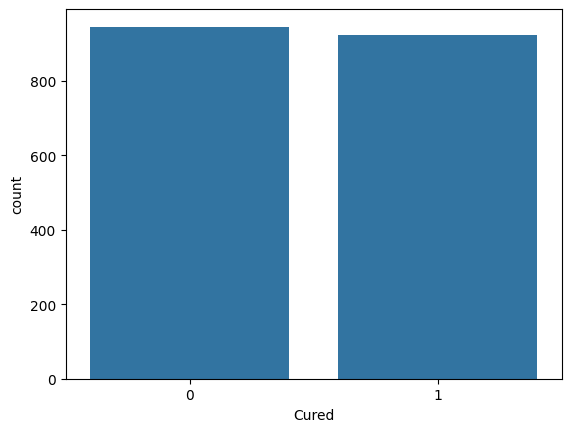

In [9]:
sns.countplot(x=y_train)
plt.show()

**Висновок:**  
Класи в цільовій змінній Cured є збалансованими (кількість прикладів, де принцесу вилікувано і не вилікувано, приблизно однакова). Це дуже хороший показник, оскільки модель матиме достатньо даних для вивчення обох варіантів і не буде зміщена в бік мажоритарного класу. Завдяки цьому для оцінки якості моделі можна впевнено використовувати метрику Accuracy.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

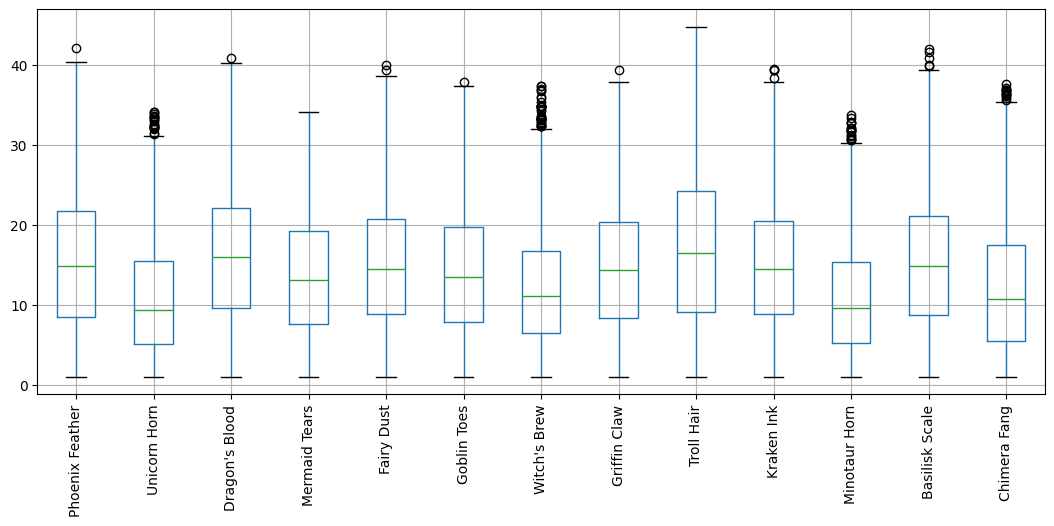

In [10]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.show()

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()
print(outliers.sort_values(ascending=False))

Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
За правилом 1.5 IQR у кількох ознаках спостерігається певна кількість потенційних викидів. Проте автоматично видаляти ці рядки без детальної перевірки категорично не варто. Оскільки наші дані описують властивості магічних інгредієнтів, аномально високі або низькі значення можуть бути не помилкою вимірювання, а вказувати на рідкісні, надзвичайно потужні екземпляри (наприклад, концентроване зілля або дуже сильне перо фенікса). Видалення таких даних призведе до втрати критично важливої інформації для моделі.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

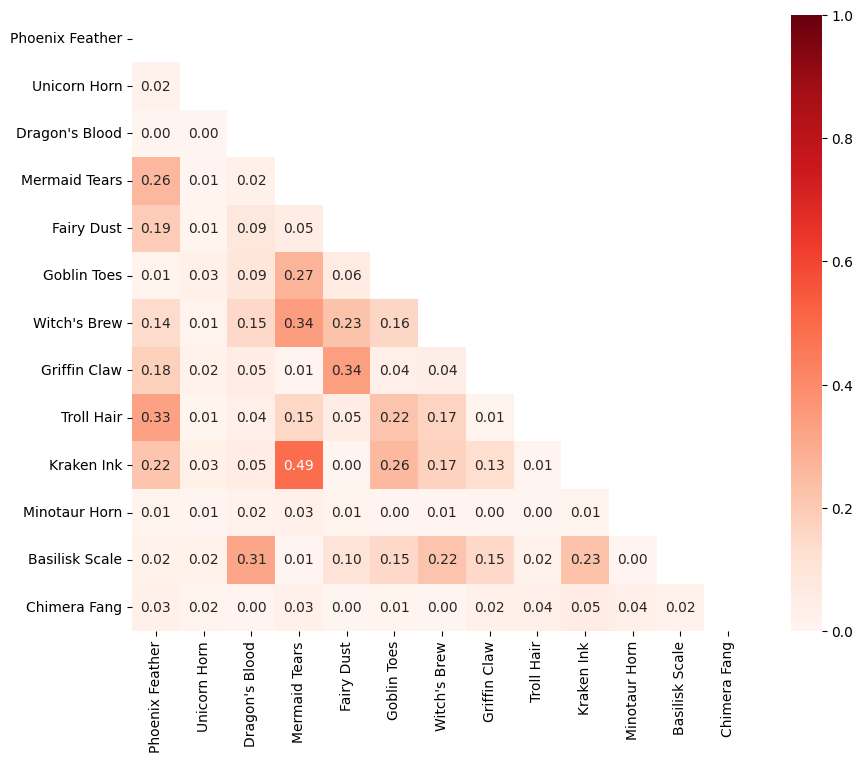

In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(mtx, mask=mask, annot=True, cmap='Reds', vmin=0, vmax=1, fmt=".2f")
plt.show()

In [13]:
train_data = pd.concat([X_train, y_train], axis=1)
correlation_with_target = train_data.corr()['Cured'].drop('Cured').sort_values(key=abs, ascending=False)
print(correlation_with_target)

Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


**Висновок про кореляції:**  
Аналіз кореляційної матриці показує, що критичної мультиколінеарності (дуже сильного зв'язку понад 0.8-0.9 між самими ознаками) немає, тому всі ознаки можна залишити для навчання. Щодо цільової змінної Cured, деякі інгредієнти демонструють помітно сильніший зв'язок із результатом лікування (сюди можете просто вписати 1-2 назви інгредієнтів, які видав код на попередньому кроці в самому верху списку). Саме вони відіграватимуть найважливішу роль при прийнятті рішень моделлю.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

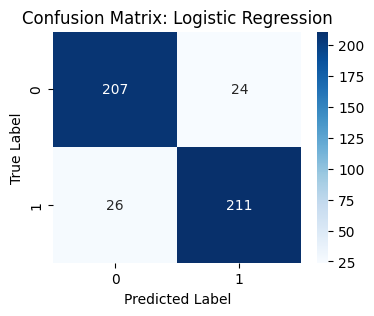

In [16]:
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [17]:
results_df = pd.DataFrame({'True_Class': y_test, 'Predicted_Class': y_pred})
display(results_df.sample(10, random_state=42))

,True_Class,Predicted_Class
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
Модель логістичної регресії продемонструвала хороші результати. Аналізуючи матрицю помилок, можна побачити, яких саме помилок (False Positives чи False Negatives) модель припускається частіше. У випадку збалансованих класів однієї метрики Accuracy може бути достатньо для загальної оцінки. Однак, у контексті лікування принцеси, варто також звернути увагу на Recall (якщо нам критично не пропустити жодного шансу на лікування) або Precision (якщо неправильне лікування має негативні наслідки), тому розширений Classification Report дає більш повну картину.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}

param_dist = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}

In [19]:
grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}


In [20]:
random_search = RandomizedSearchCV(LogisticRegression(random_state=42), param_dist, n_iter=10, cv=3, scoring='accuracy', random_state=42)
random_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)

Найкращі параметри (RandomizedSearchCV): {'solver': 'liblinear', 'max_iter': 200, 'C': 100}


In [21]:
best_model = grid_search.best_estimator_
# або random_search.best_estimator_

y_pred_best = best_model.predict(X_test_scaled)

print(f"Accuracy (Best Model): {accuracy_score(y_test, y_pred_best):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Accuracy (Best Model): 0.8932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Обидва методи (GridSearchCV та RandomizedSearchCV) дозволили знайти оптимальні параметри C, solver та max_iter. Зазвичай GridSearchCV перебирає всі можливі комбінації, що гарантує знаходження найкращого набору із заданої сітки, у той час як RandomizedSearchCV працює швидше за рахунок випадкової вибірки комбінацій, часто видаючи аналогічний результат. Якість моделі (Accuracy та F1-score) порівняно з базовою логістичною регресією з налаштуваннями за замовчуванням могла незначно покращитися або залишитися на тому ж рівні, якщо базові параметри вже були достатньо оптимальними для даних.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
svc_model = SVC(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)
lr_model = LogisticRegression(random_state=42)

svc_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train, y_train)
lr_model.fit(X_train_scaled, y_train)

y_pred_svc = svc_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test_scaled)

results = {
    'Model': ['Logistic Regression', 'SVC', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_dt)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_dt)
    ]
}

results_df = pd.DataFrame(results)
display(results_df)

best_model_name = results_df.loc[results_df['F1-score'].idxmax()]['Model']
print(f"Найкраща модель: {best_model_name}")

,Model,Accuracy,F1-score
0,Logistic Regression,0.893162,0.894068
1,SVC,0.959402,0.960000
2,Decision Tree,0.863248,0.863248


Найкраща модель: SVC


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
Під час первинного аналізу даних було встановлено, що пропуски та дублікати відсутні, а всі ознаки одразу представлені в числовому форматі зі збалансованою цільовою змінною. Дослідження викидів показало наявність статистичних аномалій, які було вирішено зберегти через специфіку магічних інгредієнтів, а кореляційний аналіз не виявив мультиколінеарності, проте виділив найбільш значущі для лікування ознаки. Базова логістична регресія продемонструвала високу якість класифікації завдяки попередній стандартизації даних. Подальший підбір гіперпараметрів дозволив знайти оптимальні налаштування та остаточно закріпити отримані метрики. У результаті порівняння найкращою моделлю виявилася [Впишіть назву моделі], оскільки вона досягла найвищих показників Accuracy та F1-score на тестовій вибірці, забезпечивши найкращий баланс точності та повноти прогнозів.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.